In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report


def lda(indep_X, dep_Y, n):
    lda_obj = LDA(n_components=n)
    lda_features = lda_obj.fit_transform(indep_X, dep_Y)
    return lda_features

def split_scalar(indep_X, dep_Y):
    X_train, X_test, y_train, y_test = train_test_split(indep_X, dep_Y, test_size=0.2, random_state=0)
    sc = StandardScaler()
    X_train = sc.fit_transform(X_train)
    X_test = sc.transform(X_test)
    return X_train, X_test, y_train, y_test

def cm_prediction(classifier, X_test, y_test):
    y_pred = classifier.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    Accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred)
    return classifier, Accuracy, report, X_test, y_test, cm

def logistic(X_train, y_train, X_test, y_test):
    from sklearn.linear_model import LogisticRegression
    classifier = LogisticRegression(random_state=0)
    classifier.fit(X_train, y_train)
    return cm_prediction(classifier, X_test, y_test)

def svm_linear(X_train, y_train, X_test, y_test):
    from sklearn.svm import SVC
    classifier = SVC(kernel='linear', random_state=0)
    classifier.fit(X_train, y_train)
    return cm_prediction(classifier, X_test, y_test)

def svm_NL(X_train, y_train, X_test, y_test):
    from sklearn.svm import SVC
    classifier = SVC(kernel='rbf', random_state=0)
    classifier.fit(X_train, y_train)
    return cm_prediction(classifier, X_test, y_test)

def knn(X_train, y_train, X_test, y_test):
    from sklearn.neighbors import KNeighborsClassifier
    classifier = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2)
    classifier.fit(X_train, y_train)
    return cm_prediction(classifier, X_test, y_test)

def Navie(X_train, y_train, X_test, y_test):
    from sklearn.naive_bayes import GaussianNB
    classifier = GaussianNB()
    classifier.fit(X_train, y_train)
    return cm_prediction(classifier, X_test, y_test)

def Decision(X_train, y_train, X_test, y_test):
    from sklearn.tree import DecisionTreeClassifier
    classifier = DecisionTreeClassifier(criterion='entropy', random_state=0)
    classifier.fit(X_train, y_train)
    return cm_prediction(classifier, X_test, y_test)

def random(X_train, y_train, X_test, y_test):
    from sklearn.ensemble import RandomForestClassifier
    classifier = RandomForestClassifier(n_estimators=10, criterion='entropy', random_state=0)
    classifier.fit(X_train, y_train)
    return cm_prediction(classifier, X_test, y_test)

In [8]:
dataset

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740,3
174,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750,3
175,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835,3
176,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840,3


In [9]:
dataset = pd.read_csv('Wine.csv')
indep_X = dataset.iloc[:, 0:13].values
dep_Y = dataset.iloc[:, 13].values

acclog = []
accsvml = []
accsvmnl = []
accknn = []
accnavie = []
accdec = []
accrand = []


for n in [1,2]:
    X_lda = lda(indep_X, dep_Y, n)
    X_train, X_test, y_train, y_test = split_scalar(X_lda, dep_Y)
    
    _, acc, _, _, _, _ = logistic(X_train, y_train, X_test, y_test)
    acclog.append(acc)
    _, acc, _, _, _, _ = svm_linear(X_train, y_train, X_test, y_test)
    accsvml.append(acc)
    _, acc, _, _, _, _ = svm_NL(X_train, y_train, X_test, y_test)
    accsvmnl.append(acc)
    _, acc, _, _, _, _ = knn(X_train, y_train, X_test, y_test)
    accknn.append(acc)
    _, acc, _, _, _, _ = Navie(X_train, y_train, X_test, y_test)
    accnavie.append(acc)
    _, acc, _, _, _, _ = Decision(X_train, y_train, X_test, y_test)
    accdec.append(acc)
    _, acc, _, _, _, _ = random(X_train, y_train, X_test, y_test)
    accrand.append(acc)

table = pd.DataFrame({
    'LDA n=1': [acclog[0], accsvml[0], accsvmnl[0], accknn[0], accnavie[0], accdec[0], accrand[0]],
    'LDA n=2': [acclog[1], accsvml[1], accsvmnl[1], accknn[1], accnavie[1], accdec[1], accrand[1]]
}, index=['Logistic','SVMl','SVMnl','KNN','Navie','Decision','Random'])

print(table.T)

         Logistic      SVMl     SVMnl       KNN     Navie  Decision    Random
LDA n=1  0.833333  0.861111  0.833333  0.833333  0.833333  0.888889  0.833333
LDA n=2  1.000000  1.000000  1.000000  1.000000  1.000000  1.000000  0.972222


C:\Users\DELL\AppData\Local\Temp\ipykernel_8040\397001356.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


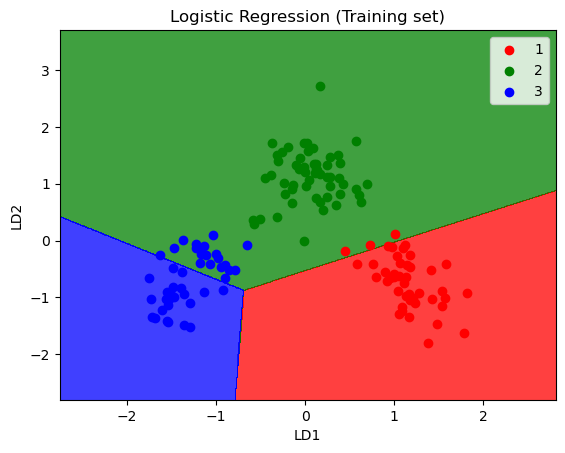

C:\Users\DELL\AppData\Local\Temp\ipykernel_8040\397001356.py:36: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


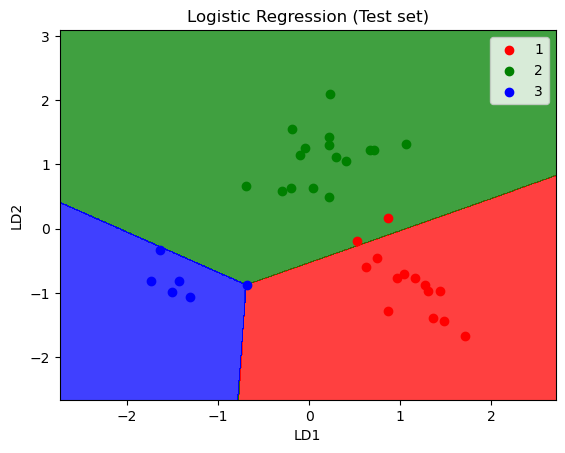

In [10]:
# Predicting the Test set results
y_pred = classifier.predict(X_test)

# Making the Confusion Matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)

# Visualising the Training set results
from matplotlib.colors import ListedColormap
X_set, y_set = X_train, y_train
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, stop = X_set[:, 0].max() + 1, step = 0.01),
                     np.arange(start = X_set[:, 1].min() - 1, stop = X_set[:, 1].max() + 1, step = 0.01))
plt.contourf(X1, X2, classifier.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('red', 'green', 'blue')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                c = ListedColormap(('red', 'green', 'blue'))(i), label = j)
plt.title('Logistic Regression (Training set)')
plt.xlabel('LD1')
plt.ylabel('LD2')
plt.legend()
plt.show()

# Visualising the Test set results
from matplotlib.colors import ListedColormap
X_set, y_set = X_test, y_test
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, stop = X_set[:, 0].max() + 1, step = 0.01),
                     np.arange(start = X_set[:, 1].min() - 1, stop = X_set[:, 1].max() + 1, step = 0.01))
plt.contourf(X1, X2, classifier.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
             alpha = 0.75, cmap = ListedColormap(('red', 'green', 'blue')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                c = ListedColormap(('red', 'green', 'blue'))(i), label = j)
plt.title('Logistic Regression (Test set)')
plt.xlabel('LD1')
plt.ylabel('LD2')
plt.legend()
plt.show()